# ドリフト速度の算出(drift_velocity.dat を作る)

TOT_Skewness は、電子が届いたクロック `clk` を µ-PIC からの距離(深さ)z に次の式で直します
(`../0_Introduction/` の座標系)。

$$ z = v\,(\mathrm{clk} - \mathrm{offset}) + 27\ \mathrm{mm} $$

- `offset` [クロック]: GEM(z = 27 mm)で電離した電子が届くクロック
- `v` [mm/クロック]: ドリフト速度。ガスの状態で少しずつ変わるので、時間(run の開始からの時間)の関数として持つ

この 2 つを書いたファイルが `drift_velocity.dat` です(設定ファイルの `TOT_Skewness.drift_velocity_file`)。

```
85                 <- 1 行目: offset [クロック]
0       0.383741   <- 時間 [時] と速度 [mm/クロック](10 分ごと)
0.166667 0.383708
...
```

このノートブックは、研究室のマクロ **`drift_speed_s2p_v3.C`** と同じ手順でこのファイルを作ります。

| 手順 | 中身 |
|---|---|
| ① クロックの分布 | 全ヒットのクロックの分布(SMILE_tool_box の `HitMap_AD/CD` の射影)。電子は GEM 面(z = 27 mm)からドリフト面(z = 27 + 305 mm)までの間で一様に生まれるので、分布は箱の形になる |
| ② 微分 | 隣のビンとの差の絶対値 \|h[b+1] − h[b]\|。箱の両端(立ち上がり・立ち下がり)が 2 つのピークになる |
| ③ offset | 0〜200 クロックで微分が最大のビン(GEM 側の端)。**アノードは 82 に固定**、カソードは最大のビン。2 つの平均を offset とする |
| ④ ドリフト面側の端 | 512〜1024 クロックの微分のピークをガウス関数でフィット。これを 10 分ごとに行う(SMILE_tool_box の `Drift_V_Anode/Cathode`) |
| ⑤ 速度 | v = 305 mm / (ドリフト面側の端 − offset)。アノード・カソードそれぞれ時間の 1 次式と 2 次式でフィットし、χ² の和が小さい方を使う。ファイルには 2 つの平均を書く |

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials_caldata" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

## 1. データの準備

データ(20190701 の較正データ **Per02**)の入手方法と置き場所は、
**[1_DataIO のノートブック](../1_DataIO/DataIO_example.ipynb) の「1. データの準備」**を見てください。
1_DataIO の手順でデータを置いていれば、ここでは何もする必要はありません。

下のセルで、設定ファイル `config/smile2p_20190701_Per02.json` が指すデータが見つかるかだけ確認します
(`MISSING` と出たら 1_DataIO の 1 節の手順でデータをコピーしてください)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/sm2+_cal_rawdata/20190701_Per02
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/param/20190528


## 2. 較正用の生データツリーを作る

較正には**全イベント**の生データツリー(`ReadData → RawTreeWriter`、中身は `../1_DataIO/modules/8_RawTreeWriter/`)を使います。
ドリフト速度とゲインマップのノートブックで同じファイルを使うので、どちらか一方で一度作れば十分です。

ターミナル(コマンドプロンプト)では、リポジトリの `run_script` ディレクトリで次を実行するのと同じです。

```bash
cd EricaNext_try/run_script
python3 run_chain.py smile2p_20190701_Per02 -o Per02_raw_cal_thr10.root --raw --compression 505 \
    --set RawTreeWriter.save_threshold=10.0 --set RawTreeWriter.save_ha=false
```

| 引数 | 意味 |
|---|---|
| `smile2p_20190701_Per02` | 設定ファイル `config/smile2p_20190701_Per02.json` |
| `-o Per02_raw_cal_thr10.root` | 出力ファイル |
| (`-n` なし) | 全イベント(Per02 は 815,657 イベント) |
| `--raw` | `ReadData → RawTreeWriter` だけを実行する |
| `--compression 505` | zstd で圧縮する |
| `--set RawTreeWriter.save_threshold=10.0` | 波形の最大値がベースライン + 10 ADU 以下のチャンネルは波形を保存しない(ファイルを小さくするため)。**電荷の閾値は 10 以上なら後から自由に変えられる**(閾値 10 以上なら、保存しなかったチャンネルの電荷はどのみち「閾値を超えるサンプルなし」になる)。小数で書く(`10` だと整数になり、型が合わずに止まる) |
| `--set RawTreeWriter.save_ha=false` | HA の ADC は保存しない(TPC の較正には使わない) |

`--set モジュール名.パラメータ名=値` は設定ファイルの値をその場で上書きするオプションです(何回でも書けます)。

**時間と大きさの目安:** 約 80 分、約 4.6 GB(データを手元のディスクに置いた場合)。
下のセルは同じコマンドを Python から実行します。出力が既にあれば再実行しません。

In [3]:
RAW = CACHE / "Per02_raw_cal_thr10.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(RAW), "--raw", "--compression", "505",
       "--set", "RawTreeWriter.save_threshold=10.0", "--set", "RawTreeWriter.save_ha=false"]
print(" ".join(cmd))
if not RAW.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()
raw = ROOT.RDataFrame("RawTreeWriter/raw", str(RAW))
print(raw.Count().GetValue(), "events")

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials_caldata/cache/Per02_raw_cal_thr10.root --raw --compression 505 --set RawTreeWriter.save_threshold=10.0 --set RawTreeWriter.save_ha=false


815657 events


## 3. 定数

手順で使う定数です。時間のビン幅は 10 分(1800 ビン / 300 時間)です。

In [4]:
LENGTH_DRIFT = 305.            # ドリフト長 [mm](GEM 面からドリフト面まで)
A_INI_CLK = 82                 # アノードの offset はこの値に固定
GAUSS_RANGE = (512., 1024.)    # ドリフト面側の端を探すクロックの範囲
INITIAL_BIN_RESCUE = (2000., 980., 15.)   # 最初の時間ビンのフィットに失敗したときの初期値(高さ, 平均, σ)
N_TIME_BIN, TIME_WIDTH = 1800, 300.       # 時間のヒストグラム: 1800 ビン / 300 時間 = 10 分
FIT_DEGREE = "auto"            # 速度の時間変化の式: "auto"(χ² の和の小さい方)、1(直線)、2(2 次式)

## 4. ヒストグラムを作る

SMILE_tool_box の RawRead2p が作っていた 2 種類のヒストグラムを、生データツリーから作ります。

| 名前 | 横軸 | 縦軸 | 1 回詰める単位 |
|---|---|---|---|
| `HitMap_AD` / `HitMap_CD` | ストリップ番号 | クロック | ヒットしたストリップ 1 本 |
| `Drift_V_Anode` / `Drift_V_Cathode` | 時間 [時] | クロック | ボードごとに、ヒットのあるクロック 1 つ |

`Drift_V` には、エンコーダーの「ヒットの記録」(ボードごと・クロックごとに 1 つ。ストリップのビットが全部 0 の記録も含む)を、
そのボードの時刻(`anode_time[ボード]`、`cathode_time[ボード]`、100 µs 単位のカウンタ)を時間に直して詰めます。
生データツリーの `rec_a_board / rec_a_clock`(カソードは `rec_c_*`)がその記録です。

815,657 イベント・約 9 億ヒットを詰めるので、Python のループではなく RDataFrame(C++ で処理される)を使います。数分かかります。

In [5]:
ROOT.gInterpreter.Declare(r"""
// ヒットの記録ごとの時刻 [時](その記録のボードの時刻。100 us 単位のカウンタ)
ROOT::RVecD record_hours(const ROOT::RVec<short>& board, const ROOT::RVec<unsigned>& board_time) {
  ROOT::RVecD t(board.size());
  for (size_t i = 0; i < board.size(); i++) t[i] = board_time[board[i]] / 1e4 / 3600.;
  return t;
}
""")

df = (raw.Define("t_a", "record_hours(rec_a_board, anode_time)")
         .Define("t_c", "record_hours(rec_c_board, cathode_time)"))
CLK = (1024, -0.5, 1023.5)
hm = {"a": df.Histo2D(("HitMap_AD", "anode;strip;clock", 384, -0.5, 383.5, *CLK), "hit_a_strip", "hit_a_clock"),
      "c": df.Histo2D(("HitMap_CD", "cathode;strip;clock", 384, -0.5, 383.5, *CLK), "hit_c_strip", "hit_c_clock")}
dv = {"a": df.Histo2D(("Drift_V_Anode", "anode;time [hour];clock", N_TIME_BIN, 0, TIME_WIDTH, *CLK), "t_a", "rec_a_clock"),
      "c": df.Histo2D(("Drift_V_Cathode", "cathode;time [hour];clock", N_TIME_BIN, 0, TIME_WIDTH, *CLK), "t_c", "rec_c_clock")}
hm = {k: v.GetValue() for k, v in hm.items()}   # ここで全イベントを 1 回だけ読む
dv = {k: v.GetValue() for k, v in dv.items()}
print("hits: anode", int(hm["a"].GetEntries()), " cathode", int(hm["c"].GetEntries()))

hits: anode 908784523  cathode 987718551


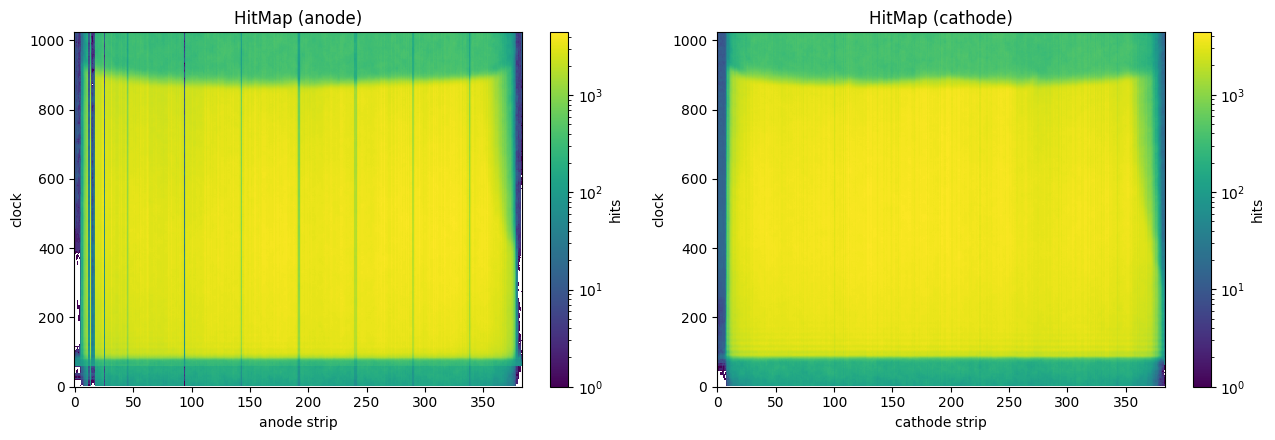

In [6]:
def th2_to_numpy(h):
    """TH2 -> (中身[nx, ny], x のビンの端, y のビンの端)"""
    nx, ny = h.GetNbinsX(), h.GetNbinsY()
    z = np.array([[h.GetBinContent(i, j) for j in range(1, ny + 1)] for i in range(1, nx + 1)])
    xe = np.array([h.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)])
    ye = np.array([h.GetYaxis().GetBinLowEdge(j) for j in range(1, ny + 2)])
    return z, xe, ye

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, side, name in zip(ax, "ac", ["anode", "cathode"]):
    z, xe, ye = th2_to_numpy(hm[side])
    m = a.pcolormesh(xe, ye, z.T, norm="log", shading="flat")
    fig.colorbar(m, ax=a, label="hits")
    a.set_xlabel(f"{name} strip"); a.set_ylabel("clock"); a.set_title(f"HitMap ({name})")
fig.tight_layout()

クロックの小さい側(約 80〜90)が GEM 面、大きい側(約 860〜880)がドリフト面です。
その間がほぼ一様(箱の形)になっています。

## 5. offset(GEM 側の端)

### 端の探し方: 隣のビンとの差

クロック b のヒットの数を h[b] とすると、分布は箱の形です(電子は GEM 面からドリフト面までの間で一様に生まれるので、その間はほぼ平ら、外はほぼ 0)。
知りたいのはこの**箱の端の位置**です。

そこで、**隣のビンとの差** d[b] = h[b+1] − h[b] を取ります(以下「微分」と呼びます)。

| 場所 | 差 d[b] |
|---|---|
| 箱の外 | ほぼ 0(0 − 0) |
| 立ち上がり(GEM 側) | 大きな正の値(急に増える) |
| 平らなところ | ほぼ 0(統計のゆらぎだけ) |
| 立ち下がり(ドリフト面側) | 大きな負の値(急に減る) |

```
h[b] : 0   0   2   950  1000  1010  ...  1000  980   3   0
差   :   0   2   948   50    10   ...    -20  -977  -3   0
```

差がいちばん大きいところが、分布がいちばん急に変わるところ = 箱の端です。
立ち下がり側は差が負になるので、**絶対値 |d[b]|** にして、両方の端を同じ向きの山にします
(GEM 側は 0〜200 クロックで最大の位置、ドリフト面側は 512〜1024 の山をガウス関数でフィット)。

下の図は、クロックの分布(上)と、その差の絶対値(下)です。差は縦軸を対数にしています。

In [7]:
def differential(h):
    """隣のビンとの差の絶対値 |h[b+1] - h[b]| のヒストグラム(次のビンがない端のビンは計算せず 0 のまま)"""
    d = h.Clone(h.GetName() + "_diff")
    d.Reset("M")
    for b in range(2, h.GetNbinsX() - 1):
        d.SetBinContent(b, abs(h.GetBinContent(b + 1) - h.GetBinContent(b)))
    return d

proj = {s: hm[s].ProjectionY(f"hit_proj_{s}") for s in "ac"}   # 全ストリップのクロック分布
diff = {s: differential(proj[s]) for s in "ac"}

d_start = {}
for s in "ac":
    diff[s].GetXaxis().SetRangeUser(0, 200)
    max_bin = diff[s].GetMaximumBin()
    diff[s].GetXaxis().UnZoom()
    found = diff[s].GetXaxis().GetBinCenter(max_bin)
    d_start[s] = A_INI_CLK if s == "a" else found          # アノードは 82 に固定
    print(f"{s}: 微分が最大のクロック = {found:.0f}  -> offset に使う値 = {d_start[s]:.0f}")
OFFSET = (d_start["a"] + d_start["c"]) / 2.
print(f"offset(平均) = {OFFSET}")

a: 微分が最大のクロック = 82  -> offset に使う値 = 82
c: 微分が最大のクロック = 88  -> offset に使う値 = 88
offset(平均) = 85.0


Warning in <TAxis::TAxis::UnZoom>: Cannot UnZoom if gPad does not exist. Did you mean to draw the TAxis first?
Warning in <TAxis::TAxis::UnZoom>: Cannot UnZoom if gPad does not exist. Did you mean to draw the TAxis first?


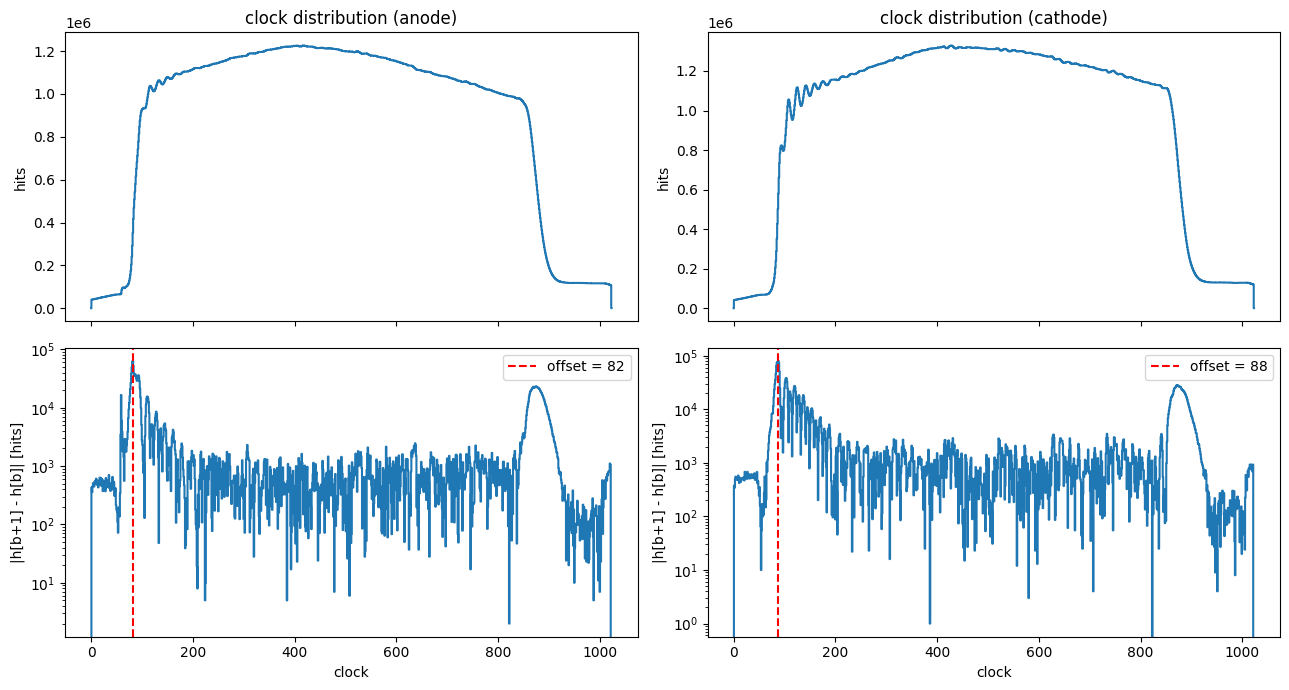

In [8]:
def th1_to_numpy(h):
    n = h.GetNbinsX()
    return (np.array([h.GetBinCenter(i) for i in range(1, n + 1)]),
            np.array([h.GetBinContent(i) for i in range(1, n + 1)]))

fig, ax = plt.subplots(2, 2, figsize=(13, 7), sharex="col")
for col, s, name in zip(range(2), "ac", ["anode", "cathode"]):
    x, y = th1_to_numpy(proj[s]); ax[0, col].step(x, y, where="mid")
    ax[0, col].set_ylabel("hits"); ax[0, col].set_title(f"clock distribution ({name})")
    x, y = th1_to_numpy(diff[s]); ax[1, col].step(x, y, where="mid")
    ax[1, col].axvline(d_start[s], color="r", ls="--", label=f"offset = {d_start[s]:.0f}")
    ax[1, col].set_xlabel("clock"); ax[1, col].set_ylabel("|h[b+1] - h[b]| [hits]"); ax[1, col].legend()
    ax[1, col].set_yscale("log")
fig.tight_layout()

## 6. ドリフト面側の端

### 6.1 全時間でのフィット(フィットの初期値を決める)

ドリフト面側の端は、512〜1024 クロックの微分の山をガウス関数でフィットして求めます。
ガウス関数のフィットは「高さ・中心・幅」を少しずつ動かして合わせるので、最初に置く値(初期値)が答えから遠いとうまく収束しません。
そこで、データから大まかな値を先に見積もります。

| 初期値 | 見積もり方(512〜1024 クロックの微分 \|d[b]\| を使う) |
|---|---|
| 高さ | 範囲の中で最大のビンの値 |
| 中心 | \|d[b]\| を重みにしたクロックの平均 |
| 幅 | 同じ重みでの RMS(ばらつき) |
| フィットの範囲 | 中心 ± 1.5 × RMS |

フィットは 2 段階です。

1. 全時間(約 6 時間分)をまとめた分布でフィットする(統計が多いので安定する)
2. その結果を初期値にして、10 分ごとの分布をフィットする(10 分ごとは統計が少ないので、答えに近いところから始める)

全時間のフィットの中心は、平らな部分のゆらぎも重みに入るため実際の端より手前に出ますが、これは初期値にしか使いません。

In [9]:
def set_fit_parameter(h, lo, hi):
    """drift_speed_s2p_v3.C の SetFitParameter: [lo, hi] のビンの (最大値, 平均, RMS) と、平均 ± 1.5 RMS の範囲"""
    max_y, s0, s1, s2 = 0., 0., 0., 0.
    for b in range(int(lo), int(hi) + 1):
        c = h.GetBinContent(b)
        max_y = max(max_y, c)
        s0 += c; s1 += b * c; s2 += b * b * c
    mean = s1 / s0
    rms = np.sqrt(s2 / s0 - mean ** 2)
    rng = [max(mean - 1.5 * rms, lo), min(mean + 1.5 * rms, hi)]
    return [max_y, mean, rms], rng

init_val, fit_range, hit_fit = {}, {}, {}
for s in "ac":
    init_val[s], fit_range[s] = set_fit_parameter(diff[s], *GAUSS_RANGE)
    f = ROOT.TF1(f"hit_fit_{s}", "gaus", *GAUSS_RANGE)
    for p in range(3):
        f.SetParameter(p, init_val[s][p])
    diff[s].Fit(f, "Q", "R", *fit_range[s])
    hit_fit[s] = f
    init_val[s] = [f.GetParameter(p) for p in range(3)]
    print(f"{s}: fit range {fit_range[s][0]:.1f}-{fit_range[s][1]:.1f}, end = {f.GetParameter(1):.2f} clock")

a: fit range 687.5-982.9, end = 835.22 clock
c: fit range 679.8-984.2, end = 831.97 clock


Warning in <ROOT::Fit::FillData>: fit range is outside histogram range, no fit data for xaxis
Warning in <Fit>: Fit data is empty 
Warning in <ROOT::Fit::FillData>: fit range is outside histogram range, no fit data for xaxis
Warning in <Fit>: Fit data is empty 


### 6.2 10 分ごとのフィット

`Drift_V` の時間のビンごとにクロックの分布を取り出し、微分のピークを同じ範囲でフィットします。
フィットがうまくいかなかったときの扱いは次のとおりです。

- フィットの中心が範囲の外、誤差が 100 以上、または前のビンの値から 0.7 % 以上ずれたときは、
  前のビンのフィット結果(±0.7 % に制限)を初期値にしてやり直す(最初のビンでは `INITIAL_BIN_RESCUE` を ±20 % に制限して使う)
- それでも範囲の外なら、その点の誤差を 100 にする(直線フィットでほぼ無視される)

最後にデータのある時間のビン(`tbin_max`)までを使います。

In [10]:
def end_clock_vs_time(h2, tbin_max, init, frange):
    """drift_speed_s2p_v3.C の GetTGraphStartEnd: 時間のビンごとのドリフト面側の端 -> (時間, 端, 誤差)"""
    pts = []
    last, last_range, last_ok = None, None, False
    for b in range(1, tbin_max + 1):
        d = differential(h2.ProjectionY(f"{h2.GetName()}_p{b}", b, b))
        f = ROOT.TF1("fit_e", "gaus", *frange)
        for p in range(3):
            f.SetParameter(p, init[p])
        f.SetParLimits(1, *frange)
        d.Fit(f, "Q", "R", *frange)
        y, ey = f.GetParameter(1), f.GetParError(1)
        if (y <= frange[0] or frange[1] <= y or ey >= 100
                or (last_ok and (y - last[1]) ** 2 > (y * 0.007) ** 2)):
            if last_ok:
                for p in range(3):
                    f.SetParameter(p, last[p]); f.SetParLimits(p, last[p] * 0.993, last[p] * 1.007)
                d.Fit(f, "Q", "R", *last_range)
            else:
                for p in range(3):
                    f.SetParameter(p, INITIAL_BIN_RESCUE[p])
                    f.SetParLimits(p, INITIAL_BIN_RESCUE[p] * 0.8, INITIAL_BIN_RESCUE[p] * 1.2)
                d.Fit(f, "Q", "R", INITIAL_BIN_RESCUE[1] - INITIAL_BIN_RESCUE[2] * 3, GAUSS_RANGE[1])
            y, ey = f.GetParameter(1), f.GetParError(1)
        if y <= frange[0] or frange[1] <= y or ey > 100:
            ey = 100.
        else:
            last = [f.GetParameter(p) for p in range(3)]
            last_range = [frange[0], frange[0]]   # 両方とも範囲の下端
            last_ok = True
        pts.append((h2.GetXaxis().GetBinCenter(b), y, ey))
    return np.array(pts)

tbin_max = dv["a"].ProjectionX("tx").FindLastBinAbove()
t_last = dv["a"].GetXaxis().GetBinLowEdge(tbin_max + 1)
print(f"データのある時間のビン: {tbin_max} 個(0 - {t_last:.3f} 時間)")
ends = {s: end_clock_vs_time(dv[s], tbin_max, init_val[s], fit_range[s]) for s in "ac"}

データのある時間のビン: 36 個(0 - 6.000 時間)


Info in <TCanvas::MakeDefCanvas>:  created default TCanvas with name c1
Info in <ROOT::Math::ParameterSettings>: lower/upper bounds outside current parameter value. The value will be set to (low+up)/2 
Info in <ROOT::Math::ParameterSettings>: lower/upper bounds outside current parameter value. The value will be set to (low+up)/2 
Info in <ROOT::Math::ParameterSettings>: lower/upper bounds outside current parameter value. The value will be set to (low+up)/2 
Info in <ROOT::Math::ParameterSettings>: lower/upper bounds outside current parameter value. The value will be set to (low+up)/2 
Info in <ROOT::Math::ParameterSettings>: lower/upper bounds outside current parameter value. The value will be set to (low+up)/2 
Info in <ROOT::Math::ParameterSettings>: lower/upper bounds outside current parameter value. The value will be set to (low+up)/2 
Info in <ROOT::Math::ParameterSettings>: lower/upper bounds outside current parameter value. The value will be set to (low+up)/2 
Info in <ROOT::Mat

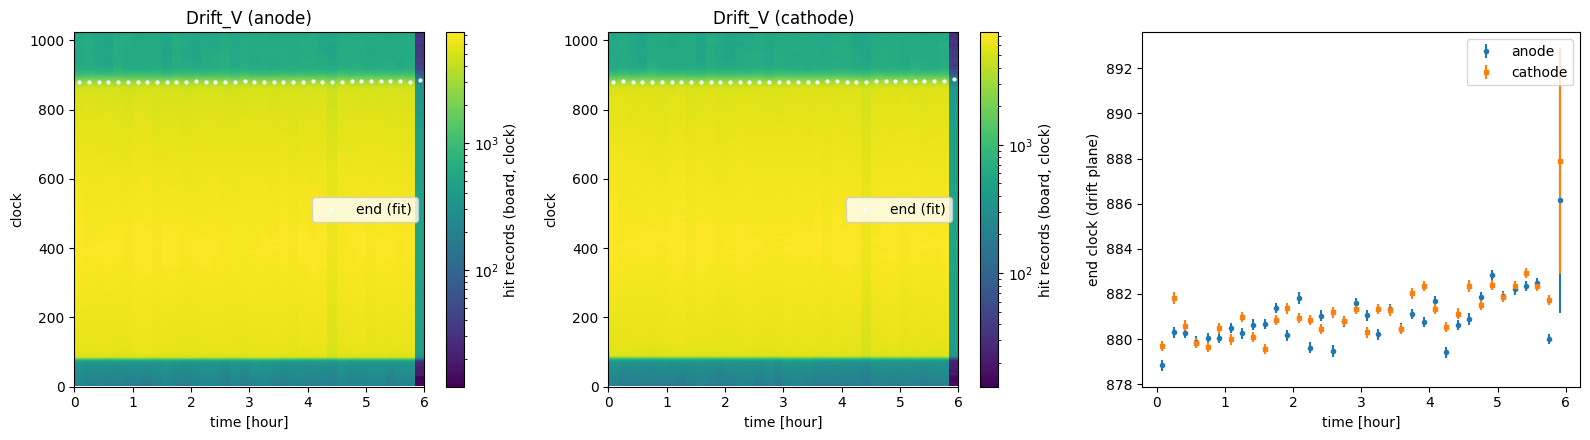

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, s, name in zip(ax[:2], "ac", ["anode", "cathode"]):
    z, xe, ye = th2_to_numpy(dv[s])
    m = a.pcolormesh(xe[:tbin_max + 1], ye, z[:tbin_max].T, norm="log", shading="flat")
    fig.colorbar(m, ax=a, label="hit records (board, clock)")
    a.plot(ends[s][:, 0], ends[s][:, 1], "w.", ms=4, label="end (fit)")
    a.set_xlabel("time [hour]"); a.set_ylabel("clock"); a.set_title(f"Drift_V ({name})"); a.legend(loc="center right")
for s, name, mk in (("a", "anode", "o"), ("c", "cathode", "s")):
    ax[2].errorbar(ends[s][:, 0], ends[s][:, 1], yerr=np.minimum(ends[s][:, 2], 5), fmt=mk, ms=3, label=name)
ax[2].set_xlabel("time [hour]"); ax[2].set_ylabel("end clock (drift plane)"); ax[2].legend()
fig.tight_layout()

左と中央の図は、**クロックの分布(箱の形)を 10 分ごとに並べたもの**です。

- 横軸: run の開始からの時間 [時]、縦軸: ヒットの記録のクロック、色: 10 分 × 1 クロックのビンに入った記録の数(対数)
- 1 本の縦の列が、その 10 分間のクロックの分布。明るい帯(約 85〜880 クロック)が GEM 面からドリフト面までの電子
- 白い点: 10 分ごとにフィットしたドリフト面側の端

ドリフト面側の端が平らに見えるのは、変化が小さいからです。この run(約 6 時間)ではドリフト速度が 0.3 % ほどしか変わらず、
端のクロック(offset + 305 mm / v)は約 880 から 882 へ、2 クロックほど動くだけです。0〜1024 の縦軸では見えないので、
右の図で端のクロックだけを拡大しています(878〜882 クロックの間でゆっくり大きくなっている)。

- この図は全ストリップを足し合わせているので、場所によるドリフトの違いは見えません(それは 4 節の HitMap の上側の端の形で見る)。
- 一番右の暗い列は、run がその 10 分の途中で終わっているため。箱の外(0〜85 と 880 以上)にも 10² 程度の記録があります
  (GEM と µ-PIC の間のギャップでできた電子やノイズ)が、端は箱の中との急な差で決めるので結果にはほとんど影響しません。

## 7. ドリフト速度

10 分ごとの端から速度 v = 305 mm / (端 − offset) を計算し(offset はアノード・カソードそれぞれの値)、
時間の 1 次式と 2 次式でフィットします(ROOT の `pol1` / `pol2`、オプション `QRO`)。
アノードとカソードの χ² の和が小さい方の式を使い、ファイルには 2 つの平均を書きます。

※ 同じ点に当てる場合、2 次式の χ² は 1 次式より大きくならないので、`FIT_DEGREE = "auto"`(既定)ではほぼ必ず 2 次式になります。
直線で表したいときは、3 節で `FIT_DEGREE = 1` にします。

In [12]:
g_vel, fits = {}, {1: {}, 2: {}}
for s in "ac":
    t, y, ey = ends[s].T
    delta = y - d_start[s]
    v, ev = LENGTH_DRIFT / delta, LENGTH_DRIFT / delta ** 2 * ey
    g = ROOT.TGraphErrors(len(t), t.astype(float), v.astype(float), np.zeros(len(t)), ev.astype(float))
    g_vel[s] = g
    for deg in (1, 2):
        if (deg == 2 and len(t) <= 2) or len(t) == 1:
            continue
        f = ROOT.TF1(f"fit_res{deg}_{s}", f"pol{deg}", 0, t_last * 1.05)
        g.Fit(f, "QRO", "", 0, t_last)
        fits[deg][s] = f

if len(ends["a"]) == 1:
    DEG = 0   # 時間のビンが 1 つだけ: フィットせず、その 1 点の速度を全時間に使う
elif FIT_DEGREE != "auto":
    DEG = FIT_DEGREE
elif len(fits[2]) < 2 or (fits[1]["a"].GetChisquare() + fits[1]["c"].GetChisquare()
                        < fits[2]["a"].GetChisquare() + fits[2]["c"].GetChisquare()):
    DEG = 1
else:
    DEG = 2
if DEG == 0:
    v_single = {s: LENGTH_DRIFT / (ends[s][0, 1] - d_start[s]) for s in "ac"}
    print("時間のビンが 1 つ: anode %.6f, cathode %.6f mm/clock" % (v_single["a"], v_single["c"]))
else:
    print("使う式: pol%d" % DEG)
    for s in "ac":
        f = fits[DEG][s]
        print(s, "parameters:", [round(f.GetParameter(p), 7) for p in range(DEG + 1)], " chi2 = %.2f" % f.GetChisquare())

def velocity(s, h):
    """フィットした速度の式(時間のビンが 1 つのときはその値)"""
    return v_single[s] if DEG == 0 else fits[DEG][s].Eval(h)

使う式: pol2
a parameters: [0.3822739, -0.0001578, 2e-07]  chi2 = 341.34
c parameters: [0.3849942, -5.28e-05, -2.31e-05]  chi2 = 220.85


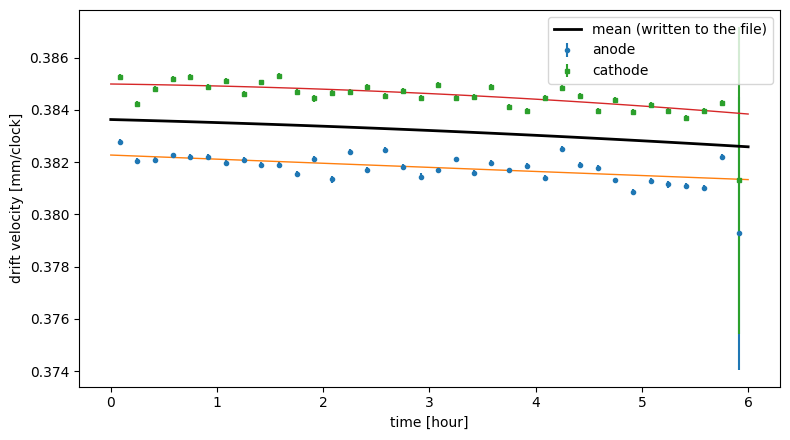

In [13]:
hours = np.array([dv["c"].GetXaxis().GetBinLowEdge(i + 1) for i in range(tbin_max + 1)])
v_mean = np.array([(velocity("a", h) + velocity("c", h)) / 2. for h in hours])

fig, ax = plt.subplots(figsize=(8, 4.5))
for s, name, mk in (("a", "anode", "o"), ("c", "cathode", "s")):
    t, y, ey = ends[s].T
    v = LENGTH_DRIFT / (y - d_start[s])
    ok = ey < 100
    ax.errorbar(t[ok], v[ok], yerr=(LENGTH_DRIFT / (y - d_start[s]) ** 2 * ey)[ok], fmt=mk, ms=3, label=name)
    ax.plot(hours, [velocity(s, h) for h in hours], "-", lw=1)
ax.plot(hours, v_mean, "k-", lw=2, label="mean (written to the file)")
ax.set_xlabel("time [hour]"); ax.set_ylabel("drift velocity [mm/clock]"); ax.legend()
fig.tight_layout()

## 8. drift_velocity.dat を書き出す

1 行目に offset、続けて時間のビンの下端 [時] と速度を書きます。
ここでは `tutorials_caldata/cache/drift_velocity_Per02.dat` に書きます。これが Per02 のドリフト速度の較正ファイルです。

作ったファイルを解析に使うときは、設定ファイルの `TOT_Skewness.drift_velocity_file` をこのファイルに書き換えるか、
`run_chain.py` に `--set TOT_Skewness.drift_velocity_file=<パス>` を付けます。

In [14]:
OUT_DAT = CACHE / "drift_velocity_Per02.dat"
with open(OUT_DAT, "w") as fout:
    fout.write(f"{OFFSET:g}\n")
    for h, v in zip(hours, v_mean):
        fout.write(f"{h:g}\t{v:g}\n")
print("wrote", OUT_DAT)

print(open(OUT_DAT).read()[:200], "...")

wrote /home/onoda/ANLNext/EricaNext_try/tutorials_caldata/cache/drift_velocity_Per02.dat
85
0	0.383634
0.166667	0.383616
0.333333	0.383598
0.5	0.383579
0.666667	0.383559
0.833333	0.383538
1	0.383517
1.16667	0.383496
1.33333	0.383473
1.5	0.38345
1.66667	0.383427
1.83333	0.383402
2	0.383378 ...
